# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [30]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

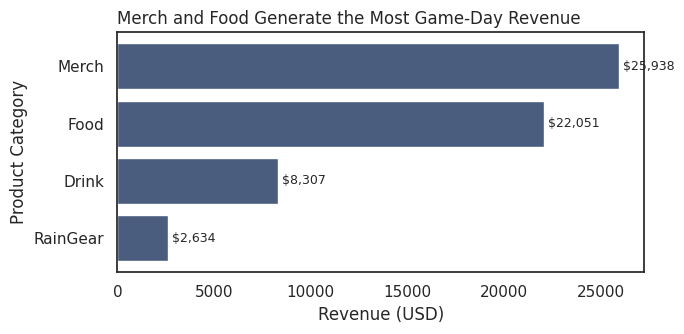

In [31]:
# Create a variable to rep the total revenue for each category
revenue = df.groupby('category')['revenue'].sum()

# Assign s to be the revenue from smallest to largest
s = revenue.sort_values()

# Form the charts with the given code from Monday
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(s.index, s.values, color=BLUE)

# Add title and axis label
ax.set_title('Merch and Food Generate the Most Game-Day Revenue', loc='left', fontsize=12)
ax.set_xlabel('Revenue (USD)')
ax.set_ylabel('Product Category')

# Add dollar amounts to the bars
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in s.values], padding=3, fontsize=9)

# Make room for the labels with tight_layout()
plt.tight_layout()
plt.show()


**Caption:** The merchandise and the food inventory should be prioritized, since these categories make up most of the game-day revenue.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

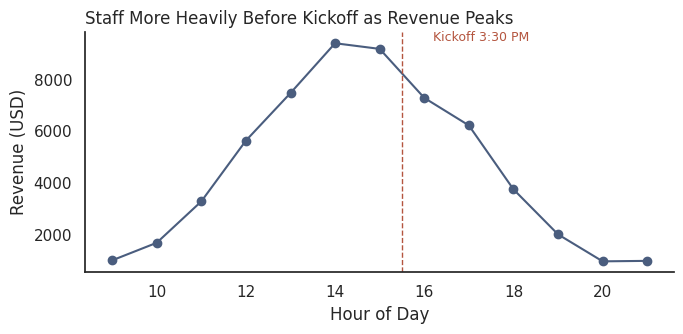

In [32]:
# Use revenue_hour to group the sum of the revenue per hour for the game
revenue_hour = df.groupby('hour')['revenue'].sum()

# Form the chart
fig, ax = plt.subplots(figsize=(7, 3.5))

# Plot revenue over time - using 'o' as the marker and changing the color of the line to blue
ax.plot(revenue_hour.index, revenue_hour.values, marker='o', color=BLUE)

# Point out that kickoff is at 3:30 PM w/ a rust color
ax.axvline(15.5, ls='--', color=RUST, lw=1)

# Add kickoff annotation
ax.annotate('Kickoff 3:30 PM', xy=(15.5, 9500), xytext=(16.2, 9500), fontsize=9, color=RUST)

# Format chart
finish(ax, 'Staff More Heavily Before Kickoff as Revenue Peaks', xlabel='Hour of Day', ylabel='Revenue (USD)')

# Show the chart
plt.show()

**Caption:** The scheduler should aim to allocate additional staff during the early afternoon, as that is when revenue is higher and the most customers are active.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

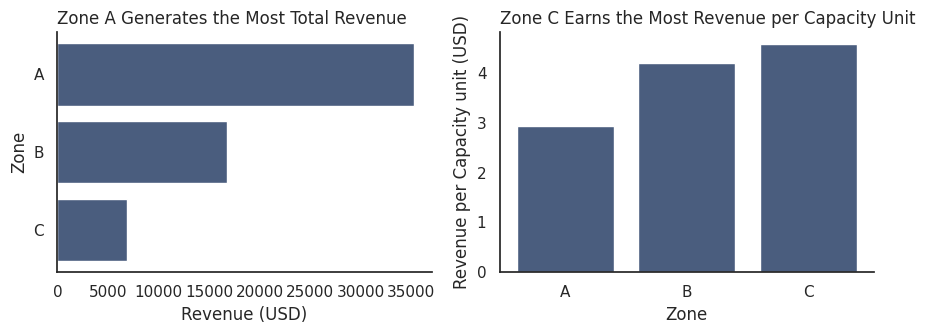

In [33]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

# Calculate the total revenue - broken down by zone
zone_revenue = df.groupby('zone')['revenue'].sum()

# Calculate the revenue per unit by the capacity given in zone_capacity
capacity = pd.Series(zone_capacity)
revenue_per_capacity = zone_revenue / capacity

# Create the two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

# Chart 1 - Total Revenue
# Sorting the raw values by smallest - largest
raw = zone_revenue.sort_values()
axes[0].barh(raw.index, raw.values, color=BLUE)
finish(axes[0], 'Zone A Generates the Most Total Revenue', xlabel='Revenue (USD)', ylabel='Zone')

# Chart 2 - Revenue per Capacity
# Creating normlaized value - revenue per capacity
normalized = revenue_per_capacity.sort_values()
axes[1].bar(normalized.index, normalized.values, color=BLUE)
finish(axes[1], 'Zone C Earns the Most Revenue per Capacity Unit', xlabel='Zone', ylabel='Revenue per Capacity unit (USD)')

**Caption, and which panel I would present:** The left chart presents the information if the viewer is more interested in which zone generates the most total revenue, while the right chart is more useful for evaluating efficiency, considering it is per Capacity unit, thus allowing the viewer to determine where additional resources may be beneficial for customer experience. I would present the normalized chart. If a manager wanted to compare zone performance fairly, the left chart would not be a fair representation, since it does not account for differences in capacity. However, if they were more interested in total revenue per zone, I would show the graph on the left. The audience's interests and objectives determine which graph is better suited.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

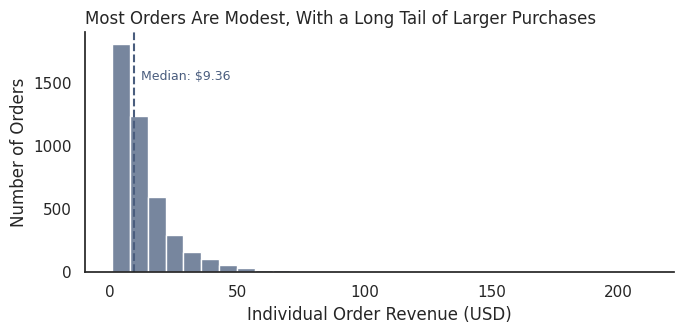

In [34]:
# Calculating the median for the order revenue
median = df['revenue'].median()

# Creating the histogram
fig, ax = plt.subplots(figsize=(7, 3.5))
# Plotting the histogram - with revenue on the x-axis
sns.histplot(data=df, x='revenue', bins=30, color=BLUE, ax=ax)

# Plot the median
ax.axvline(median, color= BLUE, ls = '--')

# Add a label for the median
ax.text(median + 3, ax.get_ylim()[1] * 0.8, f'Median: ${median:.2f}', color=BLUE, fontsize=9)

# Add the title, x and y labels
finish(ax, 'Most Orders Are Modest, With a Long Tail of Larger Purchases', xlabel='Individual Order Revenue (USD)', ylabel='Number of Orders')

# Show the chart
plt.show()

**Caption:** By using the distribution of the order values, we can see the typical customer spending, and thus use this data to identify areas of opportunity to increase revenue by suggesting larger purchases.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

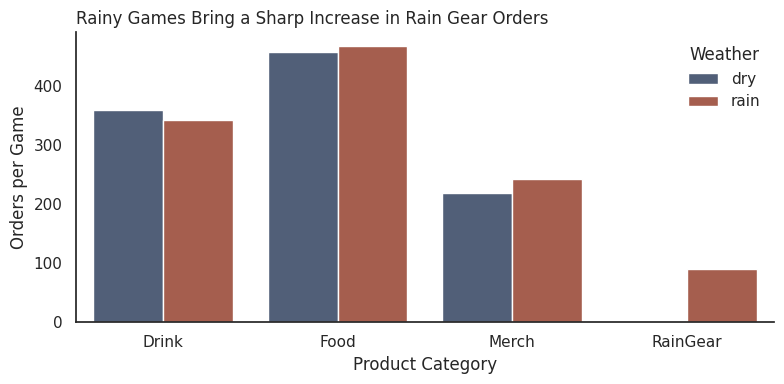

In [35]:
# Grouped Bar Chart

# Calculating the orders per game by weather and category
per_game = (df.groupby(['weather', 'category']).size().unstack('weather').div(df.groupby('weather')['game'].nunique(), axis='columns'))

# Changing the table into Sns format - long format
per_game_long = per_game.reset_index().melt(id_vars='category', var_name='weather', value_name='orders_per_game')

# Create the grouped bar chart
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=per_game_long, x='category', y='orders_per_game', hue='weather', palette={'dry': BLUE, 'rain': RUST},ax=ax)

# Create the title, x & y labels
finish(ax, 'Rainy Games Bring a Sharp Increase in Rain Gear Orders', xlabel='Product Category', ylabel='Orders per Game')

# Add a legend with title
ax.legend(title='Weather', frameon= False)

# Show the graph
plt.show()

**Caption:** There should be an increase in rain gear inventory when rain is forecast for a game, as demand rises significantly when weather conditions change.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [36]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) In chart three, it changed my perspective on the revenue generated by zone. Originally, I thought that Zone A had the strongest performance; however, when we normalized based on capacity size, Zone C has the most revenue per capacity unit. This changed my thought process and reinforced the importance of normalizing values. The total revenue alone does not show how efficiently each of the zones generated revenue.

b) In chart three, the total revenue chart would be useful when determining which zones contributed the most overall revenue. However, the normalized chart is more beneficial when comparing efficiency between zones since it takes into account the capacity sizes for each zone. If a manager wanted to use the total revenue to understand where the most money is generated, it would be more helpful to show them the graph unnormalized, but if they want to understand efficiency, graph two may be better.